# EXAFS shell analysis

Extended X-ray absorption fine structure (EXAFS) is the oscillation of the
absorption coefficient above an edge. The photoelectron leaves the absorber,
backscatters off its neighbours and interferes with itself, so the
oscillation `chi(k)` is a sum of damped sines, one per scattering path:

$$
\chi(k) = \sum_j \frac{N_j S_0^2 F_j(k)}{k R_j^2}\,
e^{-2k^2\sigma_j^2}\, e^{-2R_j/\lambda(k)}\,
\sin\!\big(2kR_j + \delta_j(k)\big)
$$

The amplitude `F_j`, phase `delta_j` and mean free path `lambda` of each path
come from a scattering code (FEFF), the structure from the fit: coordination
number `N`, distance `R`, disorder `sigma^2` and one edge shift `dE0` per
spectrum. `S0^2`, the many-body amplitude reduction, multiplies every `N`, so it
is calibrated once, on a reference whose `N` is known — a metal foil measured
under the same conditions ([Rehr & Albers 2000](https://doi.org/10.1103/RevModPhys.72.621);
[Newville, *Fundamentals of XAFS*](https://doi.org/10.2138/rmg.2014.78.2)).

The hard part is not the fit. It is deciding **which shells the data
support**. A spectrum measured to `k = 12` holds about
`2 dk dR / pi + 2 ≈ 19` independent numbers over `R = 1-4 A`
([Stern 1993](https://doi.org/10.1103/PhysRevB.48.9825)); every shell costs
three or four of them; two shells closer than `pi / (2 dk)` cannot be told
apart; and a catalogue of standards from a dozen reference compounds offers
far more combinations than the data can rank by eye. `mv.exp.exafs_*`
implements that decision as a stated procedure:

| question | function |
|---|---|
| what standards are there, and which belong together? | `mv.exp.exafs_paths` |
| what is `S0^2`? | `mv.exp.exafs_s02` |
| which shells, and what are N, R, sigma^2 with honest errors — for a whole series? | `mv.exp.exafs_series` |
| does this particular model fit, and how well? | `mv.exp.exafs_fit`, `mv.exp.exafs_agreement` |
| what are the shells (paths of one family merged)? | `mv.exp.exafs_shells` |
| paths from a structure; chi(k) from mu(E) | `mv.exp.exafs_feff_paths`, `mv.exp.exafs_chi` (xraylarch) |

The forward model is Larch's `FeffPathGroup` with linear interpolation of the
`feff.dat` columns ([Newville 2013](https://doi.org/10.1088/1742-6596/430/1/012007));
the test suite checks the two agree point by point.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import matverse as mv
from matverse import _exafs as X

mv.pl.set_style()

🔬 Starting plot initialization...


🧪 Calculators available: 12
    • emt — EMT (LGPL-2.1)
    • lj — Lennard-Jones (LGPL-2.1)
    • mace-mpa — mace-mpa (unstated)
    • mace-omat — mace-omat (unstated)
    • sevennet — sevennet (unstated)
    • chgnet — chgnet (unstated)
    • m3gnet — m3gnet (unstated)
    • m3gnet-r2scan — m3gnet-r2scan (unstated)
    • tensornet — tensornet (unstated)
    • orb — orb (unstated)
    • gpaw-pbe — gpaw-pbe (unstated)
    • gpaw-pbe-fast — gpaw-pbe-fast (unstated)
🖥️ PyTorch absent — GPU detection skipped. Machine-learned potentials need it.

                   __
   ____ ___  ____ _/ /__   _____  _____________
  / __ `__ \/ __ `/ __/ | / / _ \/ ___/ ___/ _ \
 / / / / / / /_/ / /_ | |/ /  __/ /  (__  )  __/
/_/ /_/ /_/\__,_/\__/ |___/\___/_/  /____/\___/

🔖 Version: 0.1.72   🧮 Functions: 290   📚 Tutorials: https://matverse.readthedocs.io/
✅ set_style complete.



## A path catalogue whose answers we know

Real work starts from FEFF calculations on candidate structures (Larch ships
`feff6l`; `larch.xafs.feff6l` runs it on a `feff.inp`). To be able to *check*
the analysis, this page uses smooth FEFF-like paths written in the same
`feff.dat` layout, so every answer is known. The catalogue is what a real one
looks like: each path has an id, an **equivalence group** (standards of one
chemical family — e.g. every Fe–O path, whatever compound it came from — are
interchangeable wherever their distance bounds let them reach a shell), its
scatterers, number of legs, degeneracy, `reff` and source compound.

Four compounds:

- `site` — a rigid molecular site: four N at 1.95 A, eight C at 2.98 A and
  the focusing N–C multiple-scattering path. Its shells exist **together**:
  the C shell has exactly twice the N coordination, and the multiple
  scattering follows the C shell.
- `metal` — the foil's own structure (8 + 6 metal neighbours).
- `oxide` — an oxide with a light first shell and a metal second shell.
- `sulfide` — a distractor.

In [2]:
CATALOG = {
    "site": [("N_site", "gN", "N", 2, 4.0, 1.95, 7), ("C_site", "gC", "C", 2, 8.0, 2.98, 6),
             ("MS_site", "gMS", "C-N", 3, 16.0, 3.17, 7)],
    "metal": [("M1", "gM", "Fe", 2, 8.0, 2.48, 26), ("M2", "gM", "Fe", 2, 6.0, 2.87, 26)],
    "oxide": [("O_ox", "gO", "O", 2, 6.0, 2.06, 8), ("M_ox", "gMox", "Fe", 2, 12.0, 3.05, 26)],
    "sulfide": [("S_sul", "gS", "S", 2, 6.0, 2.30, 16)],
}
work = Path(tempfile.mkdtemp())
rows = []
for comp, paths in CATALOG.items():
    for pid, grp, sc, nleg, deg, reff, z in paths:
        X.write_feffdat(work / f"{pid}.dat", X.synthetic_path(reff, z, degen=deg, nleg=nleg),
                        title=comp, scatterer=sc.split("-")[-1])
        rows.append(dict(path_id=pid, file=f"{pid}.dat", group=grp, scatterers=sc, nleg=nleg,
                         degeneracy=deg, reff_angstrom=reff, source_compound=comp))
pd.DataFrame(rows).to_csv(work / "path_catalog.csv", index=False)

lib = mv.exp.exafs_paths(work / "path_catalog.csv", sites=["site"], foil_compound="metal")
lib.table

,path_id,group,scatterers,nleg,degeneracy,reff,compound,kind,tied_to,site_only
0,N_site,gN,N,2,4.0,1.95,site,light,NaN,False
1,O_ox,gO,O,2,6.0,2.06,oxide,light,NaN,False
2,S_sul,gS,S,2,6.0,2.30,sulfide,nonmetal,NaN,False
3,M1,gM,Fe,2,8.0,2.48,metal,metal,NaN,False
4,M2,gM,Fe,2,6.0,2.87,metal,metal,NaN,False
5,C_site,gC,C,2,8.0,2.98,site,light,NaN,True
6,M_ox,gMox,Fe,2,12.0,3.05,oxide,metal,NaN,False
7,MS_site,gMS,C-N,3,16.0,3.17,site,ms,C_site,False


`exafs_paths` classifies every scatterer (light, metal, other — from the
periodic table, not a list), ties each multiple-scattering path to the
outermost single-scattering path of its compound that it visits, and builds a
**bundle** for each declared site and for the foil compound: the first two
shells with the coordination ratio the structure fixes. The site's outer shell
is `site_only` — it is never offered on its own, because a carbon shell at
2.98 A without the nitrogen shell that holds it is not that site.

Which compounds are sites is the analyst's statement, made from the
catalogue's provenance (an isolated molecular moiety, a macrocycle, a single
atom site), not from what the answer should be. The foil compound is the
structure of the reference foil.

In [3]:
lib.bundles

[(('M1', 1.0, 0), ('M2', 0.75, 1)),
 (('N_site', 1.0, 0), ('C_site', 2.0, 1), ('MS_site', 4.0, 1))]

## S0^2 from the foil

The foil's coordination numbers are crystallographic — for these paths the
degeneracies 8 and 6. Fixing them leaves `S0^2`, one edge shift, and a
distance and `sigma^2` per shell. The fit is in R space, k-weights 1, 2 and 3
at once (each weight emphasises a different part of the spectrum and together
they break the `N`–`sigma^2` correlation), and the error is the covariance
error **scaled by the square root of the reduced chi-square** counted over
independent points — the convention of Larch's `feffit` and Artemis. Without
that scaling an error computed from the stated point noise is too small by the
factor the model misses the data.

In [4]:
K = np.round(np.arange(2.5, 12.0 + 1e-9, 0.05), 4)
KF = np.round(np.arange(2.5, 14.0 + 1e-9, 0.05), 4)
S02_TRUE = 0.80
rng = np.random.default_rng(7)

def spectrum(rows, e0, k=K, noise=1e-4):
    chi = sum(X.path_chi(k, lib.paths[p], n, r, s2, e0, S02_TRUE) for p, n, r, s2 in rows)
    return {"k": k, "chi": chi + rng.normal(0, noise, k.size), "sigma": np.full(k.size, noise)}

foil = spectrum([("M1", 8, 2.47, 0.0050), ("M2", 6, 2.86, 0.0068)], e0=0.8, k=KF)
cal = mv.exp.exafs_s02(foil, lib)
print(f"S0^2 = {cal['s02']:.3f} +- {cal['s02_err']:.3f}  (true {S02_TRUE})")
pd.DataFrame(cal["paths"]).T

S0^2 = 0.800 +- 0.002  (true 0.8)


,N,R,R_err,sigma2,sigma2_err
M1,8.0,2.470151,0.000192,0.004995,0.00002
M2,6.0,2.860135,0.000133,0.006799,0.00003


The fitted foil `sigma^2` values are kept on the library: inside a sample, a
metallic phase of the same element is never **more** ordered than the bulk
foil measured under the same conditions, so they become the lower bound of the
metal bundle's disorder.

## One stated model: `exafs_fit`

When the model is known, fit it. A term is a path id, `'<path>+ms'` (the path
with its tied multiple scattering), or `'site:<compound>'` (the bundle). Tied
members carry the propagated error: the C shell's `N` error is twice the N
shell's because its `N` is twice the N shell's.

In [5]:
oxide_true = [("O_ox", 5.2, 2.03, 0.0060), ("M_ox", 7.0, 3.08, 0.0085)]
ox = spectrum(oxide_true, e0=2.0)
fit = mv.exp.exafs_fit(ox, lib, ["O_ox", "M_ox"], s02=cal["s02"])
print(f"chi2_nu = {fit['redchi']:.2f}  n_idp = {fit['n_idp']:.1f}  parameters = {fit['n_params']}")
fit["table"]

chi2_nu = 0.50  n_idp = 19.2  parameters = 7


,sample_id,path_id,coordination_number,coordination_number_err,distance_angstrom,distance_angstrom_err,sigma2_angstrom2,sigma2_angstrom2_err,delta_e0_ev,delta_e0_ev_err
0,sample,O_ox,5.200844,0.014344,2.029881,0.000139,0.006008,0.000049,1.992255,0.012294
1,sample,M_ox,6.996570,0.013761,3.079831,0.000160,0.008494,0.000026,1.992255,0.012294


`exafs_agreement` measures how well **any** table of rows reproduces a
spectrum: a normalised k-space residual at each k-weight and the complex
R-space residual `|F_model - F_data| / |F_data|`. Unobserved points (a
monochromator glitch) are bridged by straight lines in both data and model
before the transform, so a gap never enters as a step.

In [6]:
mv.exp.exafs_agreement(ox, fit["table"], lib, s02=cal["s02"])

{'k1': 0.007436598045719195,
 'k2': 0.015918698821570248,
 'k3': 0.031103416416394313,
 'rspace': 0.0027526957044788788}

## Which shells? The selection procedure

`exafs_series` does for every spectrum what an experienced analyst does by
hand, but every decision is a stated test:

1. **First shells first.** Terms (a path, a path with its tied multiple
   scattering, or a bundle) are added one at a time while the R window widens;
   a path whose `|FT|` peak would lie beyond the current window is not offered
   yet. A step must lower the BIC computed against the stated noise.
2. **Physical rules.** A shell of fewer than half a neighbour is below
   detection; a parameter on its bound is not determined; two shells of
   different terms closer than the resolution `pi / (2 dk)` are not both kept
   — except a light and a metal backscatterer, whose amplitudes and phases
   differ enough to separate (half the resolution still applies); a complete
   model keeps a margin of degrees of freedom below the independent points.
3. **Model choice.** Complete models compete by BIC on chi-square scaled by
   the best model's reduced chi-square: catalogue standards transfer
   imperfectly and point uncertainties understate the error, so the misfit,
   not the stated noise, sets the scale. Within two BIC units the simpler
   model wins.
4. **Clean-up.** Every simplification a likelihood-ratio test cannot reject
   is taken; a one-shell standard is swapped for another that reaches the same
   distance and fits better; a term left on a bound is replaced by another
   standard of its **equivalence group**, or dropped only if the
   likelihood-ratio test says the data do not need it.
5. **Edge shift.** Each spectrum's `dE0` is poorly determined and correlated
   with every `R`, so the search runs in overlapping `dE0` windows and the
   pooled candidates are refitted with the shift free.
6. **Series.** A spectrum read alone cannot determine a two-phase sample. A
   sample whose model holds no site is a **reference** for its phase, and
   every sample is re-read as site + reference phase with the shares adding
   up to one (mass balance). The phase keeps its reference's distances,
   disorder and coordination ratios; its metal neighbours share one size
   factor (small particles have fewer of them). That reading replaces the
   sample's own model unless the own model fits significantly better.

The **site fraction** is the site's first-shell `N` over its degeneracy.

Three samples: a pure site, the pure oxide, and a 35 % site / 65 % oxide
mixture whose oxide particles are smaller (fewer metal neighbours).

In [7]:
site_true = [("N_site", 4.0, 1.97, 0.0040), ("C_site", 8.0, 3.00, 0.0060), ("MS_site", 16.0, 3.19, 0.0060)]
f = 0.35
mix_true = ([(p, f * n, r, s) for p, n, r, s in site_true]
            + [("O_ox", (1 - f) * 5.2, 2.03, 0.0060), ("M_ox", (1 - f) * 0.8 * 7.0, 3.08, 0.0085)])
data = {"P1": spectrum(site_true, e0=1.0), "P2": ox, "P3": spectrum(mix_true, e0=1.5)}

res = mv.exp.exafs_series(data, lib, foil=foil, kmin=3.0, rmin=1.0, rmax=3.6,
                          e0_starts=(0.0, 3.0), beam=3, n_jobs=1)
res["table"]

[exafs] S0^2 = 0.7999 +- 0.0019 from the foil (M1, M2)


[exafs] shell selection: 3 spectra x 2 edge-shift windows on 1 worker(s)


[exafs] selection 1/6 done (P1, 3 s)


[exafs] selection 2/6 done (P1, 7 s)


[exafs] selection 3/6 done (P2, 9 s)


[exafs] selection 4/6 done (P2, 11 s)


... (13 outputs left out)

[exafs] P1: own model, 3 paths, chi2_nu=0.72, site fraction 0.999720863625863, R-space misfit 0.0043


[exafs] P2: own model, 2 paths, chi2_nu=0.39, site fraction 0.0, R-space misfit 0.0022


[exafs] P3: series model, 5 paths, chi2_nu=1.43, site fraction 0.3565298968128246, R-space misfit 0.0055


,sample_id,path_id,coordination_number,coordination_number_err,distance_angstrom,distance_angstrom_err,sigma2_angstrom2,sigma2_angstrom2_err,delta_e0_ev,delta_e0_ev_err
0,P1,N_site,3.998883,0.016004,1.969702,0.000250,0.003969,0.000062,0.982417,0.029785
1,P1,C_site,7.997767,0.032008,2.999676,0.000500,0.005980,0.000077,0.982417,0.029785
2,P1,MS_site,15.995534,0.064016,3.189676,0.000500,0.005980,0.000077,0.982417,0.029785
3,P2,O_ox,5.203776,0.012758,2.029846,0.000124,0.006016,0.000043,1.986666,0.011346
4,P2,M_ox,6.994691,0.012441,3.079774,0.000146,0.008491,0.000024,1.986666,0.011346
5,P3,N_site,1.426120,0.021983,1.972557,0.001789,0.003935,0.000119,1.531911,0.040441
6,P3,C_site,2.852239,0.043966,3.000660,0.001685,0.006020,0.000316,1.531911,0.040441
7,P3,MS_site,5.704478,0.087932,3.190660,0.001685,0.006020,0.000316,1.531911,0.040441
8,P3,O_ox,3.348474,0.029754,2.029846,0.000124,0.006016,0.000043,1.531911,0.040441
9,P3,M_ox,3.612248,0.023794,3.079774,0.000146,0.008491,0.000024,1.531911,0.040441


In [8]:
pd.DataFrame({sid: {"reading": v["reading"], "reference": v.get("reference"),
                    "site fraction": res["site_fraction"][sid], "chi2_nu": round(v["redchi"], 2),
                    "n_idp": round(v["n_idp"], 1), "R-space misfit": round(v["agreement"]["rspace"], 4)}
              for sid, v in res["samples"].items()}).T

,reading,reference,site fraction,chi2_nu,n_idp,R-space misfit
P1,own,None,0.999721,0.72,16.9,0.0043
P2,own,None,0.0,0.39,16.9,0.0022
P3,series,P2,0.35653,1.43,16.9,0.0055


`P3` was read as the site plus `P2`'s phase. Its site fraction sits close to
the true 0.35, and the oxide rows carry the complementary share: the light
first shell exactly `(1 - f)` of `P2`'s, the metal shell additionally scaled
by the size factor. A shell-by-shell fit of `P3` alone has no reason to
respect that balance.

## Shells, and how they are graded

Rows of one equivalence group whose sorted distances differ by less than a
link distance are one shell: total `N`, `N`-weighted `R`, and an effective
`sigma^2` that includes the spread of the members' distances. Errors follow to
first order.

In [9]:
mv.exp.exafs_shells(res["table"], lib, link=0.25)

,sample_id,group,N,R,sigma2,N_err,R_err,sigma2_err,paths
0,P1,gN,3.998883,1.969702,0.003969,0.016004,0.000250,0.000062,N_site
1,P1,gC,7.997767,2.999676,0.005980,0.032008,0.000500,0.000077,C_site
2,P1,gMS,15.995534,3.189676,0.005980,0.064016,0.000500,0.000077,MS_site
3,P2,gO,5.203776,2.029846,0.006016,0.012758,0.000124,0.000043,O_ox
4,P2,gMox,6.994691,3.079774,0.008491,0.012441,0.000146,0.000024,M_ox
5,P3,gN,1.426120,1.972557,0.003935,0.021983,0.001789,0.000119,N_site
6,P3,gO,3.348474,2.029846,0.006016,0.029754,0.000124,0.000043,O_ox
7,P3,gC,2.852239,3.000660,0.006020,0.043966,0.001685,0.000316,C_site
8,P3,gMox,3.612248,3.079774,0.008491,0.023794,0.000146,0.000024,M_ox
9,P3,gMS,5.704478,3.190660,0.006020,0.087932,0.001685,0.000316,MS_site


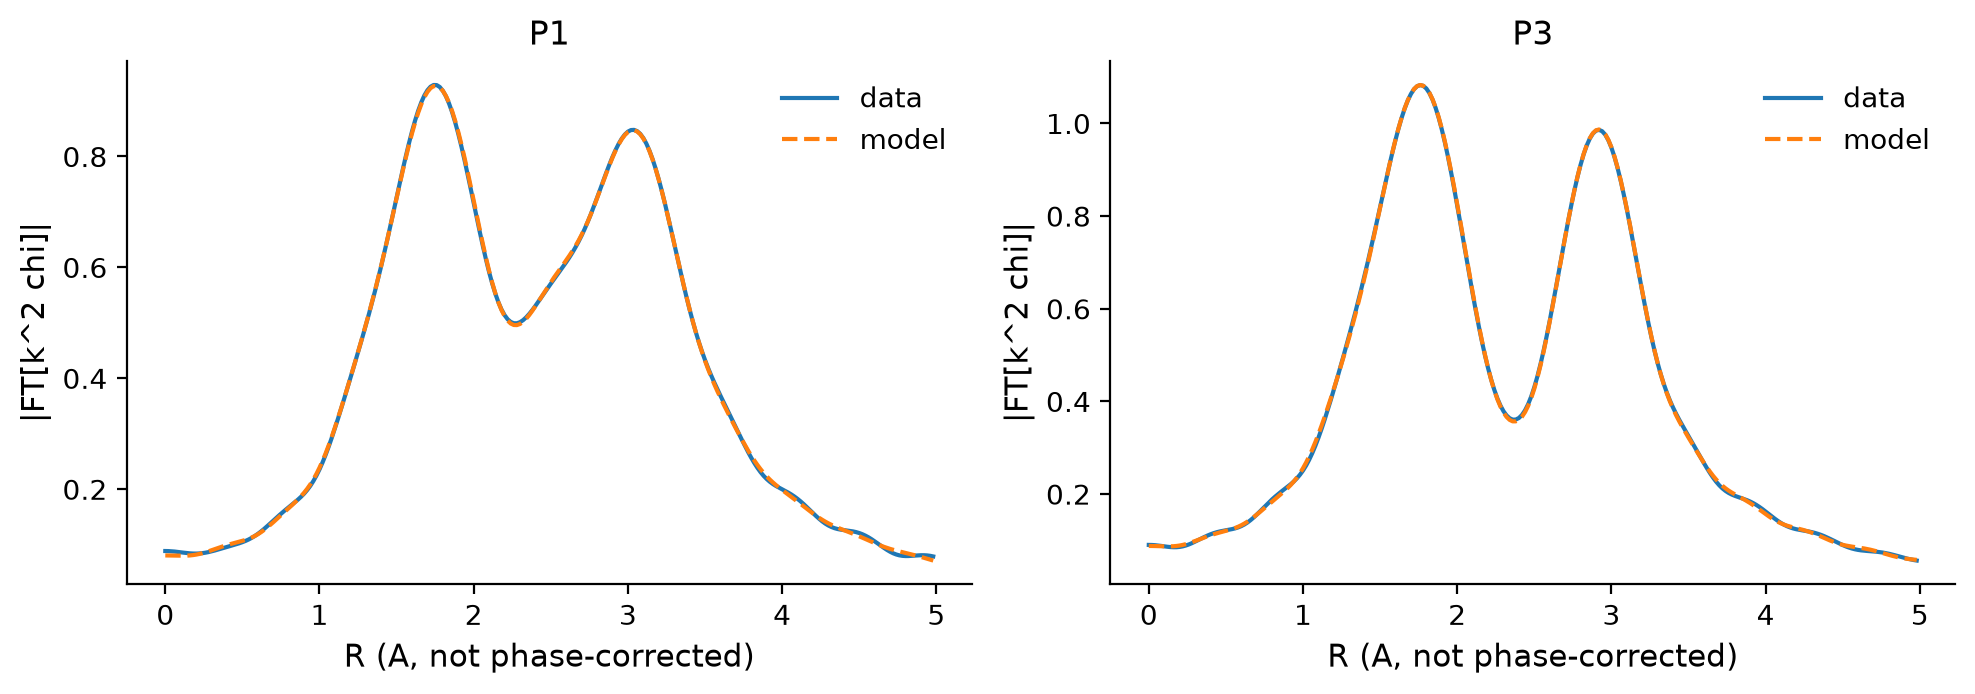

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for sid, ax in zip(("P1", "P3"), axes):
    s = data[sid]
    mine = res["table"][res["table"].sample_id == sid]
    model = X.rows_chi(lib, zip(mine.path_id, mine.coordination_number, mine.distance_angstrom,
                                mine.sigma2_angstrom2, mine.delta_e0_ev), s["k"], res["s02"])
    r = np.arange(0, 5, 0.02)
    w = X.hanning(s["k"], 3.0, s["k"].max(), 1.0) * s["k"] ** 2 * 0.05
    op = np.exp(2j * np.outer(r, s["k"])) * w
    ax.plot(r, np.abs(op @ s["chi"]), label="data")
    ax.plot(r, np.abs(op @ model), "--", label="model")
    ax.set(xlabel="R (A, not phase-corrected)", ylabel="|FT[k^2 chi]|", title=sid)
    ax.legend()
fig.tight_layout()

## Real inputs: paths from a structure, chi(k) from mu(E)

Two Larch steps sit in front of everything above.

`mv.exp.exafs_feff_paths` writes the FEFF input for one absorber in a
crystal structure (Larch's `structure2feffinp`), runs the FEFF6L that ships
with xraylarch, and returns a catalogue in the layout `exafs_paths` reads —
with the group set to the scatterer family, so standards from different
compounds that describe the same kind of neighbour share a group.
Catalogues of several structures are concatenated.

`mv.exp.exafs_chi` normalises a measured `mu(E)` (`pre_edge`) and removes the
background with AUTOBK, returning `chi(k)` on a uniform grid and a per-point
noise estimate from the high-R transform. Calibrate the energy axis against
the foil first.

In [11]:
try:
    from pymatgen.core import Lattice, Structure
    bcc = Structure.from_spacegroup("Im-3m", Lattice.cubic(2.8665), ["Fe"], [[0, 0, 0]])
    cat = mv.exp.exafs_feff_paths(bcc, "Fe", work / "feff_bcc", compound="bcc_Fe",
                                  cluster_size=5.0, rmax=4.2)
    display(cat[["path_id", "group", "scatterers", "nleg", "degeneracy", "reff_angstrom", "amp_ratio"]])

    e0 = 7112.0
    energy = np.arange(e0 - 200, e0 + 800, 0.5)
    kk = np.sqrt(np.clip(energy - e0, 0, None) * X.ETOK)
    chi_true = X.path_chi(np.maximum(kk, 0.05), lib.paths["O_ox"], 6.0, 2.03, 0.006, 0.0, S02_TRUE) * (energy > e0 + 5)
    step = 0.5 + np.arctan((energy - e0) / 2.0) / np.pi
    mu = 0.1 - 1e-5 * (energy - e0) + step * (1 - 1e-4 * np.clip(energy - e0, 0, None)) * (1 + chi_true)
    ext = mv.exp.exafs_chi(energy, mu, e0=e0, rbkg=1.0)
    print(f"E0 = {ext['e0']:.1f} eV, edge step {ext['edge_step']:.3f}, noise ~ {ext['sigma'][0]:.1e}")
except ImportError as exc:
    print("xraylarch not installed:", exc)

/opt/predeps/larch/xrd/structure2feff.py:156: DeprecationWarning: dict interface is deprecated. Use attribute interface instead
  space_group = sgroup["international"]


,path_id,group,scatterers,nleg,degeneracy,reff_angstrom,amp_ratio
0,bcc_Fe_0001,Fe-Fe,Fe,2,8.0,2.4825,100.000
1,bcc_Fe_0002,Fe-Fe,Fe,2,6.0,2.8665,55.118
2,bcc_Fe_0003,Fe-Fe-ms,Fe,3,24.0,3.9157,4.985
3,bcc_Fe_0004,Fe-Fe-ms,Fe,3,48.0,3.9157,19.311
4,bcc_Fe_0005,Fe-Fe,Fe,2,12.0,4.0538,48.989


E0 = 7112.0 eV, edge step 0.980, noise ~ 1.0e-06


## Pitfalls

- **`S0^2` and `N` are one number.** Floating both in a sample fit returns
  their product. Calibrate `S0^2` on the foil with the crystallographic `N`
  and keep it fixed.
- **`N` and `sigma^2` are correlated** (both set the amplitude). Fitting
  k-weights 1–3 together reduces the correlation; a shell with `sigma^2` on
  its upper bound and a small `N` is not detected, it is undetermined.
- **Resolution is `pi / (2 dk)`.** With `k = 3–12` two shells closer than
  0.17 A are one shell; reporting both is over-interpretation.
- **Errors without the reduced chi-square** are too small whenever the model
  misses the data by more than the noise — which is always, with transferred
  standards.
- **Equivalence groups are not decoration.** When a shell's standard ends on
  a bound, try the other standards of its group before concluding the shell
  is absent; a standard from another family that "fits as well" is a
  statement about the data's resolving power, not about the chemistry.
- **One spectrum cannot split two phases** whose shells overlap; a series
  with pure-phase references and mass balance can.
- **Runtime** grows with catalogue size x samples x edge-shift windows. For
  ~40 paths and 6 spectra expect minutes to tens of minutes on 4 CPUs: run the
  campaign once and save its table.

## References

- J. J. Rehr, R. C. Albers, *Rev. Mod. Phys.* **72**, 621 (2000).
- E. A. Stern, *Phys. Rev. B* **48**, 9825 (1993) — the number of independent points.
- M. Newville, *J. Phys.: Conf. Ser.* **430**, 012007 (2013) — Larch.
- B. Ravel, M. Newville, *J. Synchrotron Rad.* **12**, 537 (2005) — Athena/Artemis, `feffit` conventions.
- International X-ray Absorption Society, *Error reporting recommendations* (2000).